In [1]:
import pandas as pd
import wandb

api = wandb.Api()
entity, project = "dmldeep", "DoublemlDeep_CDSM_01"
runs = api.runs(entity + "/" + project)

summary_list, config_list, name_list, hist_list = [], [], [], []
for run in runs:
    summary_list.append(run.summary._json_dict)
    config_list.append(
        {k: v for k,v in run.config.items()
         if not k.startswith('_')})
    name_list.append(run.name)
    if run.state == "finished":
        hist = []
        for i, row in run.history(keys=["Cont. DoubleML Estimator"]).iterrows():
            hist.append(row["Cont. DoubleML Estimator"])
    else:
        hist = []
    hist_list.append(hist)
runs_df = pd.DataFrame({
    "summary": summary_list,
    "config": config_list,
    "name": name_list,
    "Cont. DoubleML Estimator": hist_list,
    })

In [2]:
runs_df.head()

,summary,config,name,Cont. DoubleML Estimator
0,"{'R2_ml_l': 0.5577465970878899, 'precision': '...","{'lr': 4e-05, 'optim': 'AdamW', 'momentum': 0....",helpful-pond-12,"[-0.19991515454646774, -0.3769419042662413, -0..."
1,"{'_wandb': {'runtime': 2997}, 'validation': 0....","{'lr': 3e-05, 'optim': 'AdamW', 'momentum': 0....",light-hill-13,"[0.38298674965053076, 0.19806227048835356, -0...."
2,"{'lr': 2e-05, 'ImgModel': 'DoubleMLDeepBeitMod...","{'lr': 2e-05, 'optim': 'AdamW', 'momentum': 0....",vocal-salad-14,"[-0.3238345223545996, -0.5992941386391935, -0...."
3,"{'lr': 3e-05, 'R2_ml_l': 0.5616237959183348, '...","{'lr': 3e-05, 'optim': 'AdamW', 'momentum': 0....",charmed-donkey-15,"[-0.4916606714432302, -0.1429710046580727, -0...."
4,"{'train_combined_loss': 0.6844265460968018, 't...","{'lr': 3e-05, 'optim': 'AdamW', 'momentum': 0....",soft-snowball-16,"[-0.05029492354244489, -0.5117459737355792, -0..."


In [3]:
def label_runs(row):
	txt = "txt"
	img = "img"
	tab = "tab"
	if row['TxtModel'] == 'NoneType':
		txt = ""
	if row['ImgModel'] == 'NoneType':
		img = ""
	if row['TabModel'] == 'NoneType':
		tab = ""
	return txt + img + tab

In [4]:
df = runs_df.join(runs_df["summary"].apply(pd.Series), lsuffix='', rsuffix='_last') 
df["models"] = df.apply(label_runs, axis=1)
dfg = df.groupby("models").apply(lambda x: x.nsmallest(5, 'val_combined_loss')).reset_index(drop=True)
dfg = dfg.groupby("models")

C:\Users\BAT0150\AppData\Local\Temp\ipykernel_23680\454782492.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  dfg = df.groupby("models").apply(lambda x: x.nsmallest(5, 'val_combined_loss')).reset_index(drop=True)


In [5]:
dfg["name"].count()

models
img          5
imgtab       5
txt          5
txtimg       5
txtimgtab    5
txttab       5
Name: name, dtype: int64

In [26]:
dfg[["R2_ml_l", "R2_ml_m"]].agg(["max", "mean", "std"])

R2_ml_l                       R2_ml_m                    
                max      mean       std       max      mean       std
models                                                               
img        0.156083  0.122727  0.031231  0.472772  0.449296  0.025737
imgtab     0.500898  0.451802  0.029158  0.528449  0.508530  0.028751
txt        0.468485  0.439753  0.027392  0.620900  0.612734  0.009072
txtimg     0.471865  0.416947  0.045831  0.648420  0.627548  0.017598
txtimgtab  0.599052  0.582924  0.015012  0.676489  0.653216  0.018445
txttab     0.587168  0.557419  0.025485  0.639382  0.618870  0.014864

In [23]:
dfg["theta_ln_p"].agg("mean")

models
img         -0.255423
imgtab      -0.272109
txt         -0.186863
txtimg      -0.228224
txtimgtab   -0.279416
txttab      -0.213707
Name: theta_ln_p, dtype: float64

In [24]:
dfg["theta_ln_p"].agg("std")

models
img          0.026140
imgtab       0.037777
txt          0.035469
txtimg       0.048988
txtimgtab    0.043585
txttab       0.053523
Name: theta_ln_p, dtype: float64

In [8]:
order = ["img", "imgtab", "txtimg", "txt", "txttab", "txtimgtab"]

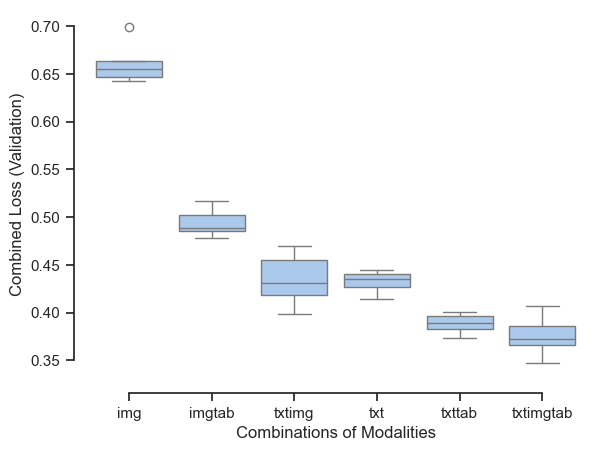

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

# plt.style.use('ggplot')

sns.set_theme(style="ticks", palette="pastel", color_codes=True)

ax = sns.boxplot(x="models", 
            y="val_combined_loss",
            data=df, 
            order=order,
            )

ax.set(xlabel='Combinations of Modalities', 
       ylabel='Combined Loss (Validation)')
sns.despine(offset=10, trim=True)
plt.show()

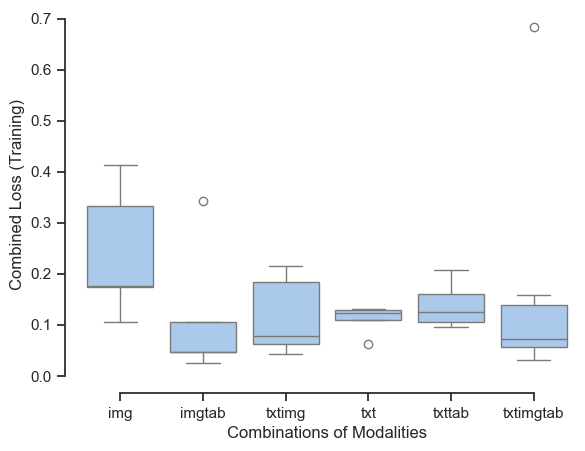

In [10]:
ax = sns.boxplot(x="models", 
                 y="train_combined_loss", 
                 order=order, 
                 data=df)
ax.set(xlabel="Combinations of Modalities", 
       ylabel="Combined Loss (Training)")
sns.despine(offset=10, trim=True)

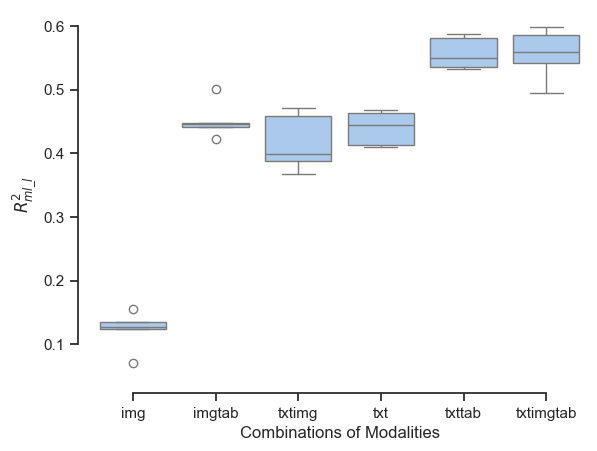

In [11]:
ax = sns.boxplot(x="models", 
                 y="R2_ml_l",
                 order=order,
                 data=df)
ax.set(xlabel='Combinations of Modalities', 
       ylabel='$R^2_{ml\_l}$')
sns.despine(offset=10, trim=True)

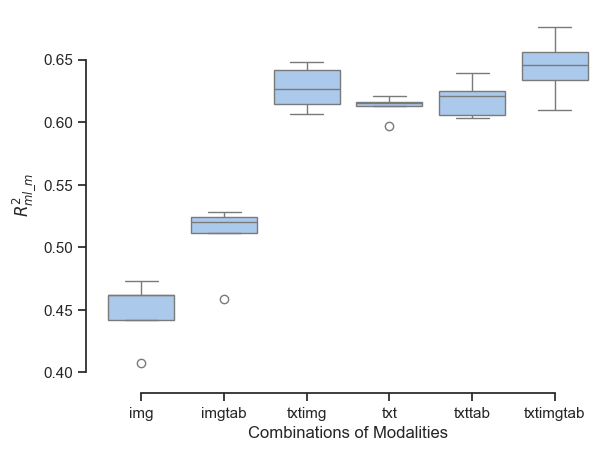

In [12]:
ax = sns.boxplot(x="models", 
                 y="R2_ml_m",
                 order=order,
                 data=df)
ax.set(xlabel='Combinations of Modalities', 
       ylabel="$R^2_{ml\_m}$")
sns.despine(offset=10, trim=True)

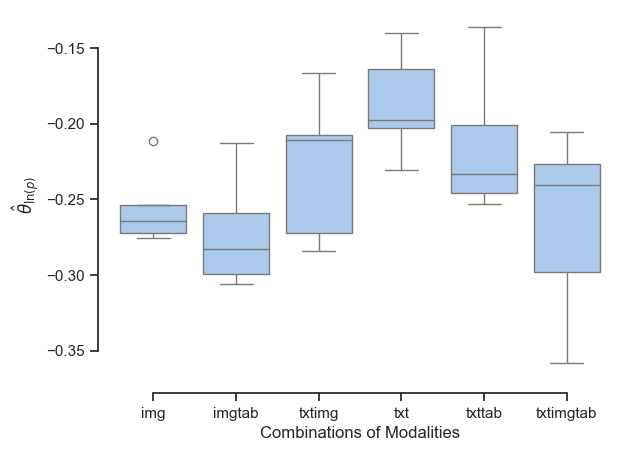

In [13]:
ax = sns.boxplot(x="models", 
                 y="theta_ln_p",
                 order=order,
                 data=df)
ax.set(xlabel='Combinations of Modalities', 
       ylabel="$\hat{\\theta}_{\ln(p)}$")
sns.despine(offset=10, trim=True)

In [14]:
df.columns


Index(['summary', 'config', 'name', 'Cont. DoubleML Estimator', 'R2_ml_l',
       'precision', 'fusion_head', 'train_RMSE_ml_m_ln_p', 'test', 'R2_ml_m',
       '_runtime', 'val_RMSE_ml_m_ln_p', 'train_RMSE_ml_l_ln_p', 'lr', 'epoch',
       'TxtModel', 'batch_size', 'validation', 'freeze_txt_model',
       'val_combined_loss', 'val_RMSE_ml_l_ln_p',
       'CI 97.5 % (ln_p) (embedding)', 'P>|t|(ln_p)', 'CI 2.5 % (ln_p)',
       'freeze_img_model', 'P>|t|(ln_p) (embedding)',
       'Cont. DoubleML Estimator_last', '_wandb', '_timestamp',
       'trainer/global_step', 'theta_ln_p (embedding)',
       'CI 2.5 % (ln_p) (embedding)', 'optim', 'TabModel', 'train', 'ImgModel',
       'theta_ln_p', 'num_workers', 'CI 97.5 % (ln_p)', 'train_combined_loss',
       '_step', 'ScoreType', 'dataset_csv', 'models'],
      dtype='object')

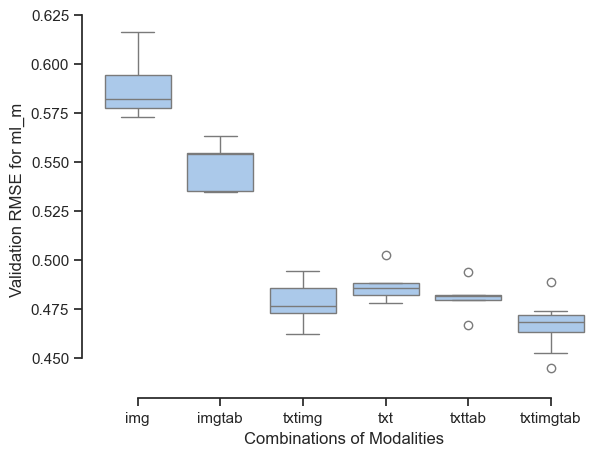

In [15]:
ax = sns.boxplot(x="models", 
                 y="val_RMSE_ml_m_ln_p",
                 order=order,
                 data=df)
ax.set(xlabel='Combinations of Modalities', 
       ylabel="Validation RMSE for ml_m")
sns.despine(offset=10, trim=True)

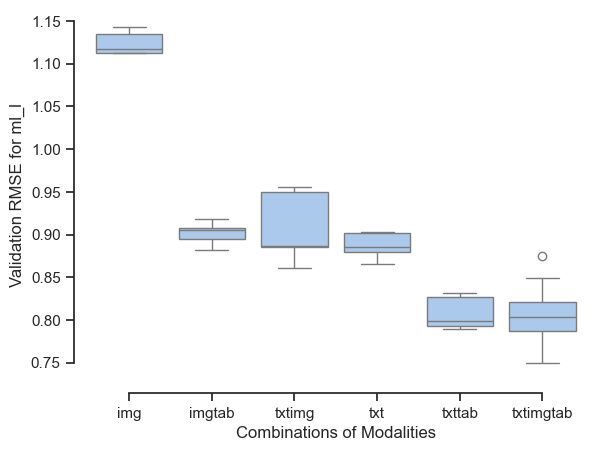

In [16]:
ax = sns.boxplot(x="models", 
                 y="val_RMSE_ml_l_ln_p",
                 order=order,
                 data=df)
ax.set(xlabel='Combinations of Modalities', 
       ylabel="Validation RMSE for ml_l")
sns.despine(offset=10, trim=True)

In [17]:
cont_dml = df[['name', 'models', 'Cont. DoubleML Estimator']].explode("Cont. DoubleML Estimator").reset_index().rename(columns={'index' : 'Epoch'})
cont_dml['Epoch'] = cont_dml.groupby('name').cumcount()
cont_dml.dropna(inplace=True)
# cont_dml = cont_dml.groupby("name")
cont_dml

,Epoch,name,models,Cont. DoubleML Estimator
0,0,helpful-pond-12,txtimgtab,-0.199915
1,1,helpful-pond-12,txtimgtab,-0.376942
2,2,helpful-pond-12,txtimgtab,-0.30592
3,3,helpful-pond-12,txtimgtab,-0.19087
4,4,helpful-pond-12,txtimgtab,-0.272381
...,...,...,...,...
407,5,lucky-yogurt-51,txtimgtab,-0.323646
408,6,lucky-yogurt-51,txtimgtab,-0.264625
409,7,lucky-yogurt-51,txtimgtab,-0.239669
410,8,lucky-yogurt-51,txtimgtab,-0.239061


<Axes: xlabel='Epoch', ylabel='Cont. DoubleML Estimator'>

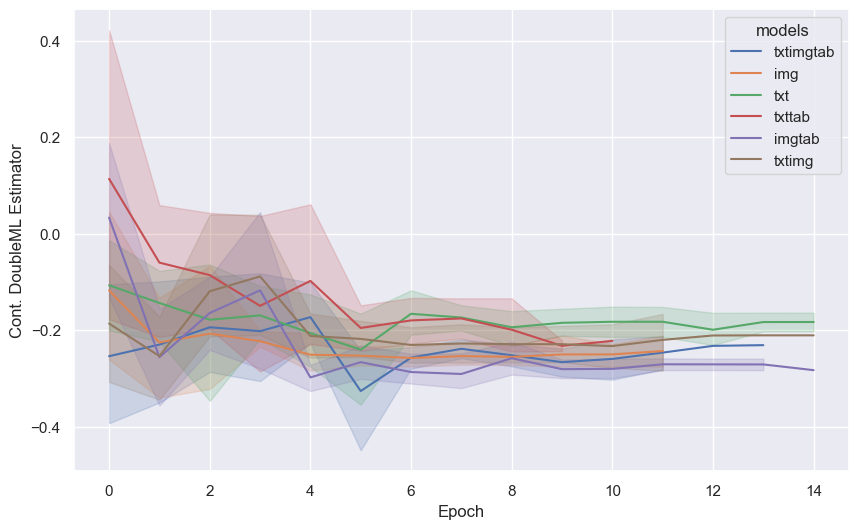

In [18]:
sns.set_theme(color_codes=True)
plt.figure(figsize=(10,6))
sns.lineplot(x='Epoch', 
             y='Cont. DoubleML Estimator', 
             hue='models', 
             data=cont_dml,
             legend=True)

<Axes: xlabel='Epoch', ylabel='Cont. DoubleML Estimator'>

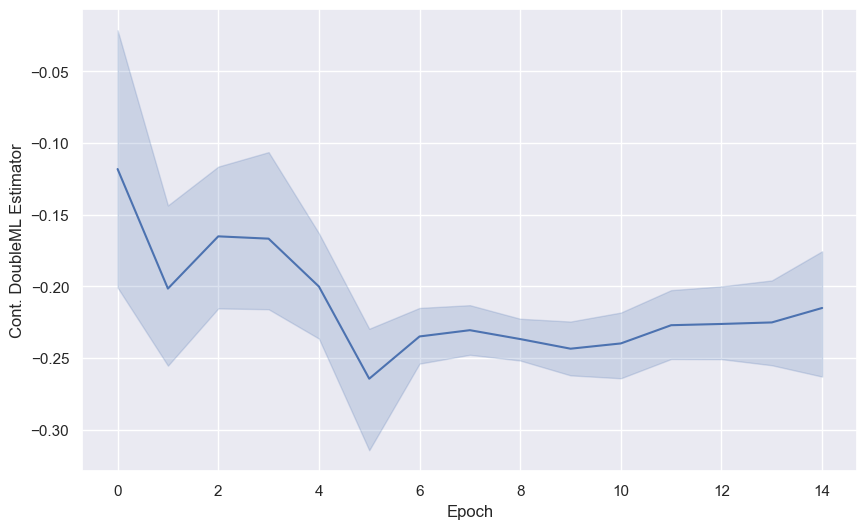

In [19]:
plt.figure(figsize=(10,6))
sns.lineplot(x='Epoch', 
             y='Cont. DoubleML Estimator', 
             # hue='models', 
             data=cont_dml,
             legend=True)

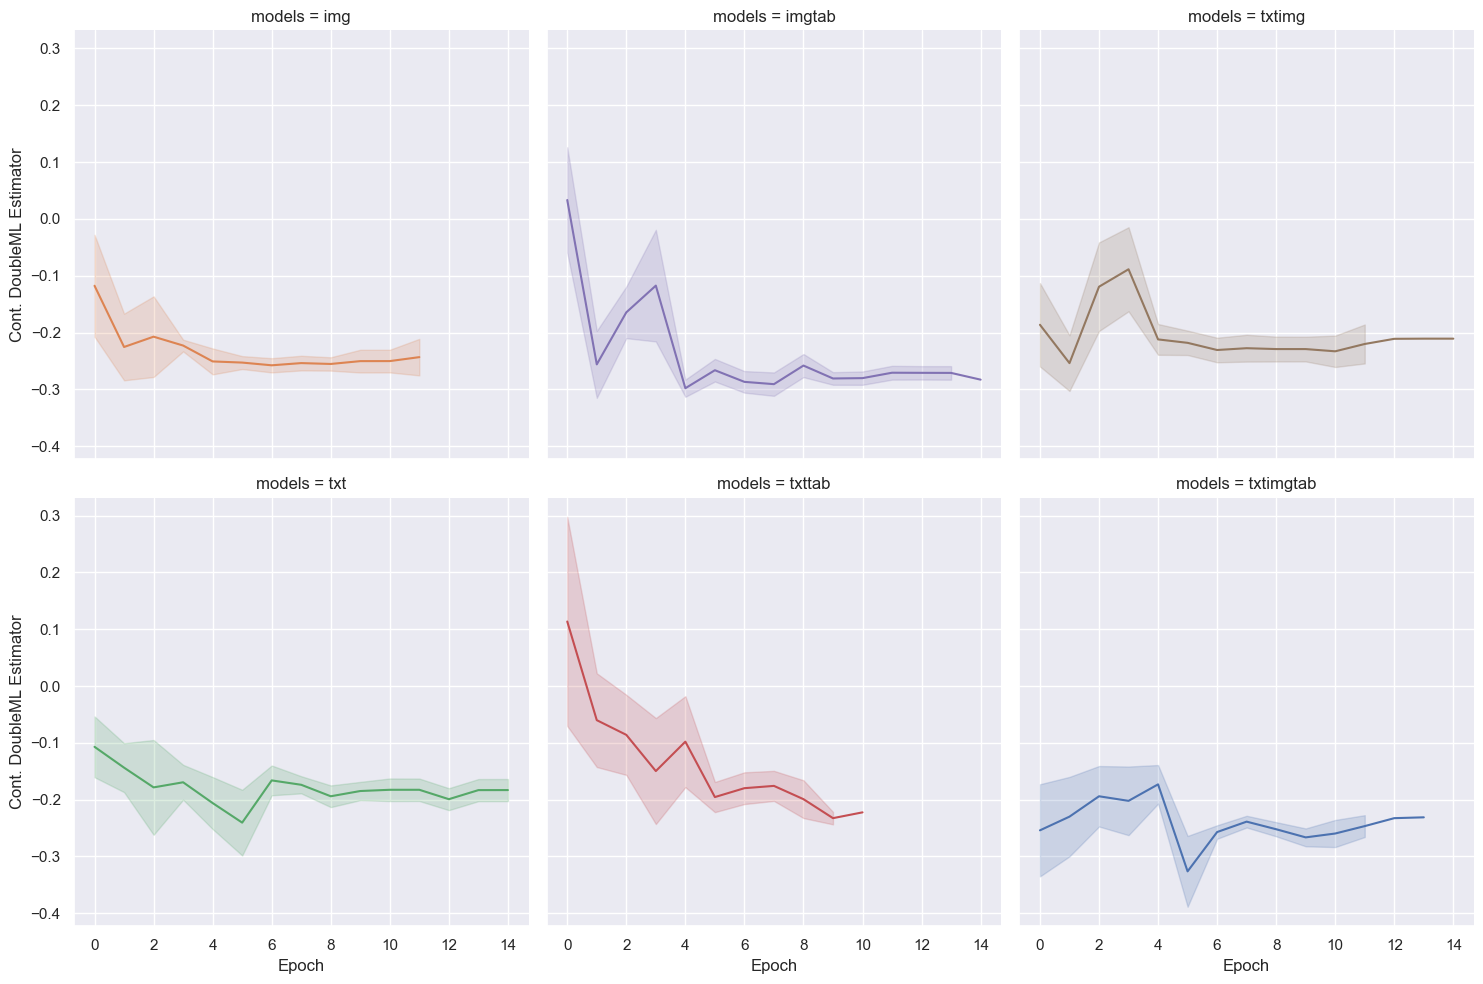

In [20]:
sns.relplot(data=cont_dml, 
            x='Epoch', 
            y='Cont. DoubleML Estimator', 
            hue='models', 
            kind='line',
            col='models', 
            col_wrap=3,
            col_order=order,
            errorbar="se",
            legend=False,
        )

In [21]:
import pandas as pd

data = {
    'Model': ['OLS', 'DoubleMLPLR', 'DoubleMLPLRDeep'],
    'Covariates': ['-', 'X=X_{tab}', 'X=(X_{tab}, X_{txt}, X_{img})'],
    'R^2_{l_0}': [0.330, 0.5986, 0.5990],
    'R^2_{m_0}': [None, 0.1884, 0.6765],
    'theta_hat_0': [-0.0455, -0.1098, -0.2794]
}

df = pd.DataFrame(data)

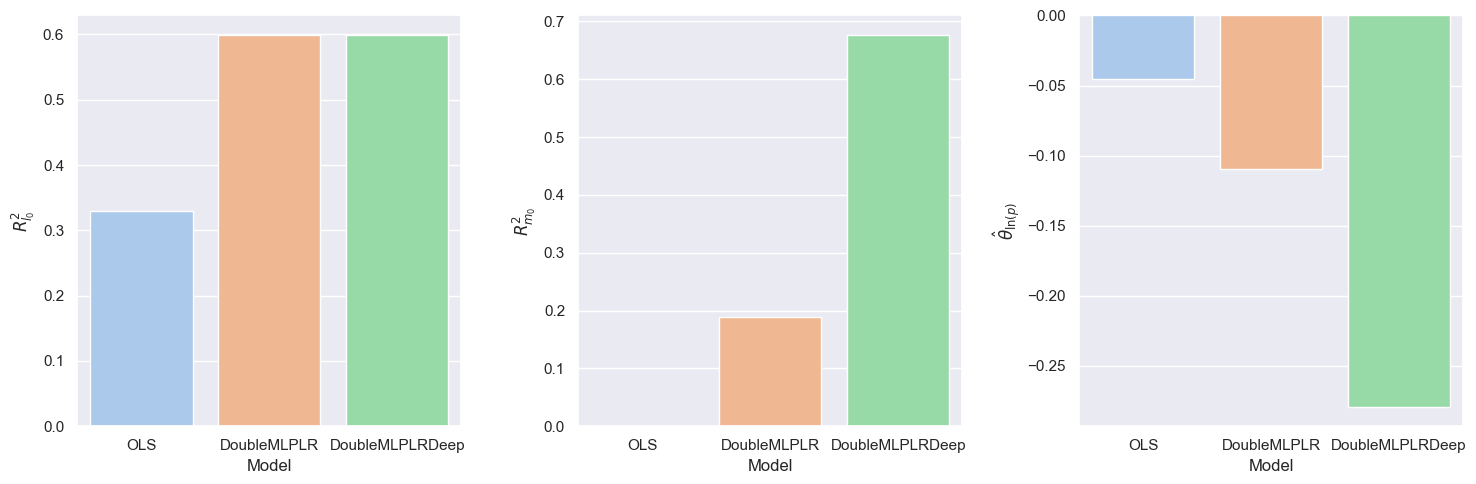

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

sns.set_theme(style="ticks", palette="pastel", color_codes=True)

# Create a bar plot for each numerical column
sns.barplot(x='Model', y='R^2_{l_0}', data=df, ax=axs[0], hue='Model')
sns.barplot(x='Model', y='R^2_{m_0}', data=df, ax=axs[1], hue='Model')
sns.barplot(x='Model', y='theta_hat_0', data=df, ax=axs[2], hue='Model')

axs[0].set(ylabel="$R^2_{l_0}$")
axs[1].set(ylabel="$R^2_{m_0}$")
axs[2].set(ylabel="$\hat{\\theta}_{\ln(p)}$")

plt.tight_layout()
plt.show()